# 🌧️ ¿Calcular o pensar con datos? Una experiencia con el clima de Caucasia

**Ponencia:** *De las tablas de frecuencia a la inteligencia artificial: enseñar estadística para desarrollar el pensamiento computacional en primaria y bachillerato*

---

### Intención de este cuaderno
Hacer **visible** la diferencia entre dos maneras de enseñar la misma estadística:

| | Enseñar a **calcular** | Enseñar a **pensar estadísticamente** |
|---|---|---|
| Punto de partida | «Hoy vamos a calcular la media» | Una pregunta sobre un fenómeno del territorio |
| Éxito significa | El resultado numérico es correcto | Se entiende qué dice (y qué oculta) el resultado |
| Rol de Python | Hacer la cuenta más rápido | Explorar, contrastar, verificar y cuestionar |
| El estudiante termina con… | Un número | Una explicación, sus límites y nuevas preguntas |

### Ruta (tres niveles de exigencia sobre los *mismos* datos)
1. **Nivel 1 · Calcular:** ejecutar el procedimiento correctamente.
2. **Nivel 2 · Interpretar:** relacionar la media con la distribución, la mediana y la dispersión.
3. **Nivel 3 · Investigar:** formular preguntas, reconocer límites y decidir qué datos faltan.
4. **Horizonte · IA:** predecir, medir el error y evaluar con datos que el modelo no ha visto.

> ⚠️ **Aviso sobre los datos.** Los datos de este cuaderno son **simulados**: reproducen un régimen plausible para el Bajo Cauca (calor constante, época más seca entre diciembre y marzo y lluvias fuertes entre abril y noviembre), pero **no son registros observados** ni están calibrados con estaciones oficiales. Sirven para enseñar. Al final de la sección 0 se explica cómo reemplazarlos por registros reales.

**Cómo usarlo:** ejecuta las celdas en orden (`Shift + Enter`). Donde veas ✋ **Detente**, discute antes de seguir. Funciona en Jupyter, JupyterLab y Google Colab (requiere `numpy`, `pandas`, `matplotlib` y `scikit-learn`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Paleta de la presentación
AMBAR, TEAL, OSCURO = "#E09F1F", "#0E7C86", "#0B2E36"
CORAL, PIZARRA = "#D1495B", "#6B7F8A"

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
})
pd.options.display.float_format = "{:,.2f}".format
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

## 0 · Los datos: tres años de clima diario (simulado)

Antes de analizar, una pregunta de pensamiento estadístico: **¿de dónde vienen los datos y qué tan lejos están de la realidad?**
La función siguiente *genera* los datos; leerla es parte de la actividad (¿qué supuestos hace? ¿qué variables relaciona?).

In [2]:
import numpy as np
import pandas as pd

def simular_caucasia(semilla=2026):
    """Genera 3 años de datos diarios SIMULADOS con un régimen plausible para el Bajo Cauca
    (calor constante, época más seca entre diciembre y marzo, lluvias fuertes entre abril y noviembre).
    NO son registros observados: sirven para enseñar."""
    rng = np.random.default_rng(semilla)
    fechas = pd.date_range("2023-01-01", "2025-12-31", freq="D")
    mes = fechas.month.values

    # Probabilidad de que un día sea lluvioso y lluvia media de un día lluvioso (mm), por mes
    p_lluvia = np.array([.25, .28, .40, .62, .75, .65, .62, .68, .72, .80, .78, .45])[mes - 1]
    mm_medio = np.array([7, 8, 10, 12, 14, 13, 12, 13, 13, 15, 15, 9])[mes - 1]

    llueve = rng.random(len(fechas)) < p_lluvia
    forma = 0.7                                   # forma < 1  ->  muchos días de poca lluvia y pocos muy fuertes
    mm = np.minimum(rng.gamma(forma, mm_medio / forma), 120)   # tope físico razonable
    precipitacion = np.where(llueve, mm, 0.0).round(1)

    humedad = (68 + 18 * llueve + 0.15 * np.minimum(precipitacion, 30)
               + 8 * p_lluvia + rng.normal(0, 3.5, len(fechas)))
    humedad = np.clip(humedad, 45, 100).round(0)
    temp_max = (41 - 0.105 * humedad + rng.normal(0, 0.8, len(fechas))).round(1)
    temp_min = (23.5 + 0.8 * p_lluvia + rng.normal(0, 0.7, len(fechas))).round(1)

    return pd.DataFrame({"fecha": fechas, "precipitacion_mm": precipitacion,
                         "temp_max_C": temp_max, "temp_min_C": temp_min,
                         "humedad_pct": humedad})

df = simular_caucasia()
df["anio"] = df["fecha"].dt.year
df["mes"] = df["fecha"].dt.month

print(f"Filas (días): {len(df)}  |  Del {df['fecha'].min():%d/%m/%Y} al {df['fecha'].max():%d/%m/%Y}")
display(df.head())

Filas (días): 1096  |  Del 01/01/2023 al 31/12/2025


,fecha,precipitacion_mm,temp_max_C,temp_min_C,humedad_pct,anio,mes
0,2023-01-01,13.90,31.10,25.20,92.00,2023,1
1,2023-01-02,0.00,34.60,25.10,65.00,2023,1
2,2023-01-03,0.00,35.80,24.70,63.00,2023,1
3,2023-01-04,0.00,34.90,22.80,74.00,2023,1
4,2023-01-05,0.00,32.30,23.50,71.00,2023,1


In [3]:
# ── Opcional: usar registros reales ───────────────────────────────────────────
# Si consigues una serie diaria real (por ejemplo, del IDEAM o de NASA POWER; revisa sus condiciones de uso),
# guárdala como CSV con estas columnas y cambia USAR_DATOS_REALES a True:
#   fecha, precipitacion_mm, temp_max_C, temp_min_C, humedad_pct
USAR_DATOS_REALES = False
RUTA_CSV = "caucasia_real.csv"

if USAR_DATOS_REALES:
    df = pd.read_csv(RUTA_CSV, parse_dates=["fecha"])
    df["anio"], df["mes"] = df["fecha"].dt.year, df["fecha"].dt.month
    print("Usando datos reales:", len(df), "días")
else:
    print("Usando datos SIMULADOS (no son registros observados de Caucasia).")

Usando datos SIMULADOS (no son registros observados de Caucasia).


### Caja de herramientas: tres funciones (pensamiento computacional en acción)

| Función | Componente del pensamiento computacional |
|---|---|
| `indicadores(serie)` | **Abstracción:** decidir qué medidas necesitamos para describir lluvia (no solo la media). |
| `buscar_meses_parecidos(df)` | **Algoritmo + automatización:** recorrer todos los pares de meses y escoger el más revelador. |
| `racha_seca_maxima(serie)` | **Algoritmo:** un procedimiento paso a paso que cuenta días secos consecutivos. |

In [4]:
from itertools import combinations

def indicadores(serie):
    """Resume una serie de precipitación con varias miradas (no solo la media)."""
    s = pd.Series(serie, dtype=float)
    return pd.Series({
        "Total (mm)": s.sum(),
        "Media (mm/día)": s.mean(),
        "Mediana (mm/día)": s.median(),
        "Desv. estándar (mm)": s.std(ddof=0),
        "Máximo diario (mm)": s.max(),
        "Días sin lluvia": int((s == 0).sum()),
        "Días con ≥ 20 mm": int((s >= 20).sum()),
        "% del total en el día más lluvioso": 100 * s.max() / s.sum(),
    })

def buscar_meses_parecidos(df, tolerancia=0.15):
    """Algoritmo: entre todos los pares de meses con casi la misma media diaria,
    elige el par cuyo comportamiento (dispersión) más se diferencia."""
    mensual = df.groupby(df["fecha"].dt.to_period("M"))["precipitacion_mm"].agg(
        media="mean", desv=lambda s: s.std(ddof=0))
    mejor = None
    for a, b in combinations(mensual.index, 2):
        if abs(mensual.loc[a, "media"] - mensual.loc[b, "media"]) <= tolerancia:
            diferencia = abs(mensual.loc[a, "desv"] - mensual.loc[b, "desv"])
            if mejor is None or diferencia > mejor[2]:
                mejor = (a, b, diferencia)
    return mejor[0], mejor[1]

def racha_seca_maxima(serie):
    """Algoritmo: cuenta la mayor cantidad de días seguidos sin lluvia."""
    maxima = actual = 0
    for valor in serie:
        if valor == 0:
            actual += 1
            maxima = max(maxima, actual)
        else:
            actual = 0
    return maxima

---
## Nivel 1 · Enseñar a **calcular**

*Consigna típica de una clase centrada en el procedimiento:* **«Calcula la precipitación media diaria de 2024.»**

Primero a mano (algoritmo con un ciclo) y luego verificamos con NumPy.

In [5]:
precip_2024 = df.loc[df["anio"] == 2024, "precipitacion_mm"]

suma = 0
for valor in precip_2024:          # el algoritmo que haría un estudiante: sumar...
    suma += valor
media_manual = suma / len(precip_2024)   # ...y dividir entre el número de datos

print(f"Media calculada a mano : {media_manual:.2f} mm/día")
print(f"Media con NumPy        : {np.mean(precip_2024):.2f} mm/día")
print("✔ Procedimiento correcto.")

Media calculada a mano : 6.64 mm/día
Media con NumPy        : 6.64 mm/día
✔ Procedimiento correcto.


In [6]:
# Otra tarea típica: "completa la tabla de medias mensuales"
medias_2024 = df[df["anio"] == 2024].groupby("mes")["precipitacion_mm"].mean()
tabla = pd.DataFrame({"Mes": MESES, "Media (mm/día)": medias_2024.values})
display(tabla.T)

,0,1,2,3,4,5,6,7,8,9,10,11
Mes,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
Media (mm/día),1.85,2.53,5.58,11.32,11.20,4.70,7.62,10.65,5.92,9.53,7.14,1.49


### ✋ Detente: ¿qué entendimos del fenómeno?
El estudiante hizo **todo bien**. Ahora responde, sin mirar más datos:

1. ¿Significa que en Caucasia llovieron ≈ 6.6 mm *cada día* de 2024?
2. ¿Qué diferencia hay entre una semana tranquila y un aguacero de 90 mm si ambos aportan a la misma media?
3. Si fueras agricultor, conductor o gestor del riesgo, ¿qué decisión tomarías con esa tabla?

> **Calcular** produjo números correctos; todavía no produjo **comprensión**.

---
## Nivel 2 · Enseñar a **interpretar**

### El experimento: dos semanas con la *misma* media
Tomamos las semanas hipotéticas del guion de la ponencia (milímetros de lluvia por día, lunes a domingo):

* **Semana A:** `0, 2, 0, 5, 0, 28, 7`
* **Semana B:** `6, 6, 6, 6, 6, 6, 6`

Primero veamos lo que ve un estudiante que **solo calcula**.

In [7]:
semana_A = np.array([0, 2, 0, 5, 0, 28, 7])
semana_B = np.array([6, 6, 6, 6, 6, 6, 6])
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

solo_calculo = pd.DataFrame({
    "Semana": ["A", "B"],
    "Días": [len(semana_A), len(semana_B)],
    "Total (mm)": [semana_A.sum(), semana_B.sum()],
    "Media (mm/día)": [semana_A.mean(), semana_B.mean()],
})
display(solo_calculo.set_index("Semana"))

,Días,Total (mm),Media (mm/día)
Semana,,,
A,7,42,6.00
B,7,42,6.00


### ✋ Detente: predice antes de ver
Conociendo **únicamente** el total y la media:

* ¿Crees que las semanas A y B se *parecieron* en lo que vivieron los habitantes de Caucasia?
* ¿Cuántos días sin lluvia crees que tuvo cada una? ¿Cuál fue el día más lluvioso de cada una?

*Anota tu predicción (o levanta la mano: «se parecieron» / «no se parecieron») y recién entonces ejecuta la siguiente celda.*

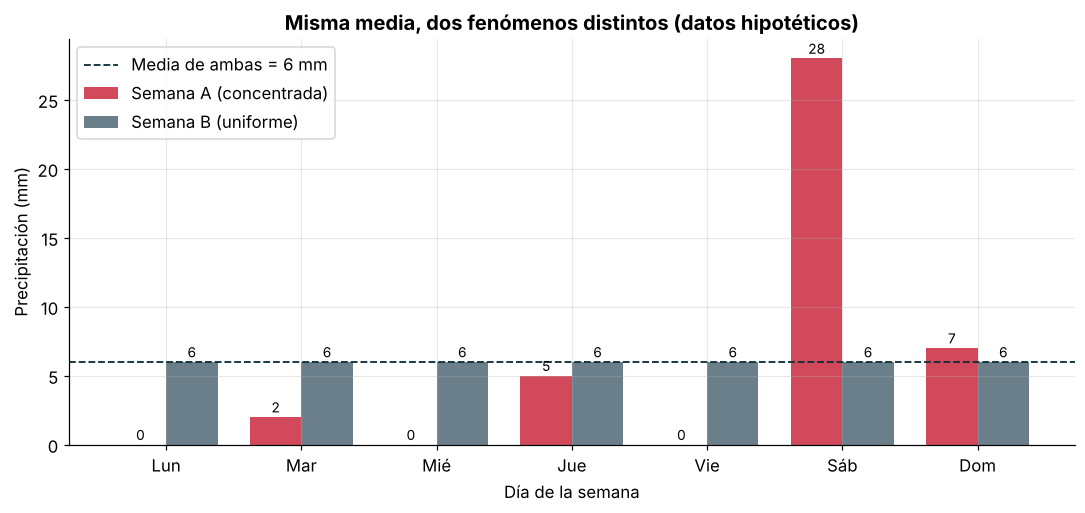

,Semana A,Semana B
Total (mm),42.00,42.00
Media (mm/día),6.00,6.00
Mediana (mm/día),2.00,6.00
Desv. estándar (mm),9.34,0.00
Máximo diario (mm),28.00,6.00
Días sin lluvia,3.00,0.00
% del total en el día más lluvioso,66.67,14.29


In [8]:
fig, ax = plt.subplots(figsize=(10, 4.8))
x, ancho = np.arange(7), 0.38
barras_A = ax.bar(x - ancho/2, semana_A, ancho, color=CORAL, label="Semana A (concentrada)")
barras_B = ax.bar(x + ancho/2, semana_B, ancho, color=PIZARRA, label="Semana B (uniforme)")
for b in list(barras_A) + list(barras_B):
    ax.annotate(f"{b.get_height():.0f}", (b.get_x() + b.get_width()/2, b.get_height()),
                xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.axhline(6, color=OSCURO, ls="--", lw=1.2, label="Media de ambas = 6 mm")
ax.set_xticks(x); ax.set_xticklabels(dias)
ax.set_ylabel("Precipitación (mm)"); ax.set_xlabel("Día de la semana")
ax.set_title("Misma media, dos fenómenos distintos (datos hipotéticos)")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

tabla_AB = pd.DataFrame({"Semana A": indicadores(semana_A), "Semana B": indicadores(semana_B)})
display(tabla_AB.loc[["Total (mm)", "Media (mm/día)", "Mediana (mm/día)", "Desv. estándar (mm)",
                      "Máximo diario (mm)", "Días sin lluvia", "% del total en el día más lluvioso"]])

### Lectura estadística (lo que la media escondía)

* **Mediana:** la Semana A tiene mediana de 2 mm; la media (6 mm) está *arrastrada* por un solo día extremo.
* **Dispersión:** la desviación estándar de A es ≈ 9.3 mm; la de B es 0.
* **Concentración:** el 67 % de lo que llovió en A cayó en **un solo día**.
* **Consecuencias distintas:** 28 mm en un día puede saturar un drenaje urbano o cerrar una vía rural; 6 mm diarios no.

> Con una sola medida resumen no se distinguen. **Pensar estadísticamente es preguntar qué información falta para comprender el fenómeno.**

### Del ejemplo de juguete a los datos de Caucasia
¿Pasa lo mismo con datos «reales»? En vez de inventar dos semanas, **le pedimos al computador que las busque**: entre los 36 meses de la serie, ¿qué dos meses tienen casi la misma media diaria pero comportamientos más distintos?

El algoritmo encontró: 2023-10 y 2024-04


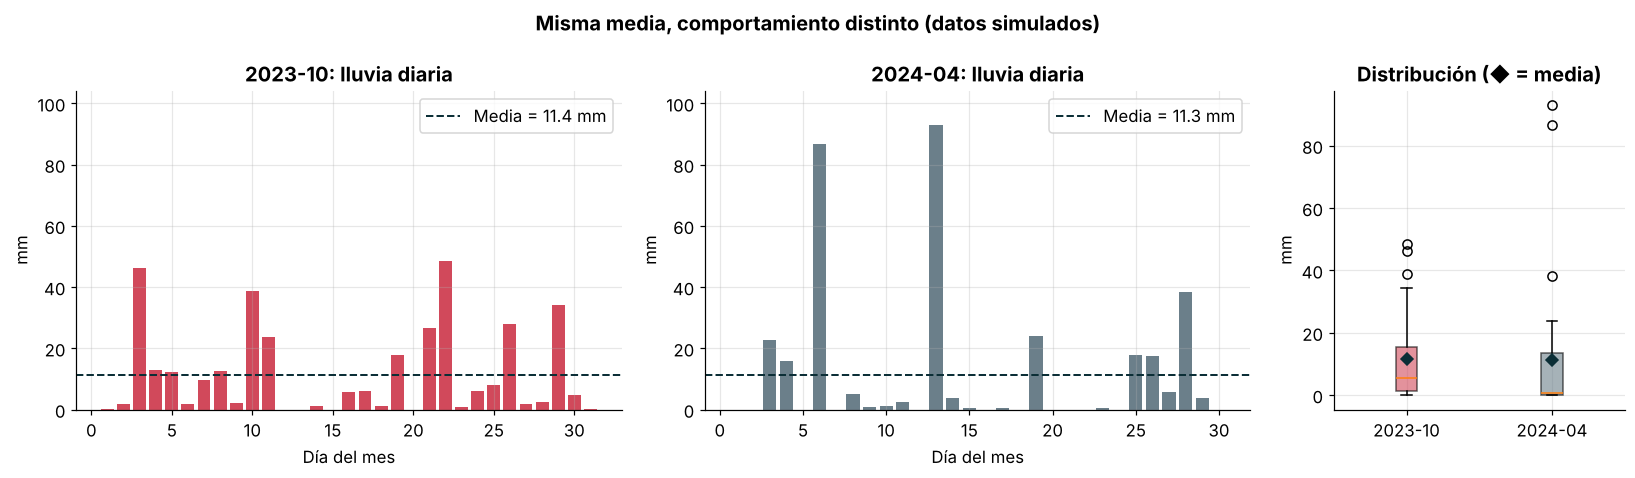

,2023-10,2024-04
Total (mm),354.40,339.70
Media (mm/día),11.43,11.32
Mediana (mm/día),5.60,0.60
Desv. estándar (mm),14.18,22.97
Máximo diario (mm),48.50,93.00
Días sin lluvia,4.00,12.00
Días con ≥ 20 mm,7.00,5.00
% del total en el día más lluvioso,13.69,27.38
Racha seca máxima (días),2.00,3.00


In [9]:
def comparar_periodos(df, periodo_a, periodo_b):
    """Compara dos meses (formato 'AAAA-MM') con gráficos e indicadores."""
    datos = {}
    for p in (periodo_a, periodo_b):
        datos[p] = df[df["fecha"].dt.to_period("M") == pd.Period(p)]["precipitacion_mm"].reset_index(drop=True)

    fig, ejes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [3, 3, 1.6]})
    tope = max(s.max() for s in datos.values()) * 1.12
    for eje, (p, s), color in zip(ejes[:2], datos.items(), (CORAL, PIZARRA)):
        eje.bar(np.arange(1, len(s) + 1), s, color=color)
        eje.axhline(s.mean(), color=OSCURO, ls="--", lw=1.3, label=f"Media = {s.mean():.1f} mm")
        eje.set_ylim(0, tope); eje.set_title(f"{p}: lluvia diaria")
        eje.set_xlabel("Día del mes"); eje.set_ylabel("mm"); eje.legend(loc="upper right")
    caja = ejes[2].boxplot(list(datos.values()), tick_labels=list(datos.keys()), patch_artist=True,
                           showmeans=True, meanprops=dict(marker="D", markerfacecolor=OSCURO, markeredgecolor=OSCURO))
    for parche, color in zip(caja["boxes"], (CORAL, PIZARRA)):
        parche.set_facecolor(color); parche.set_alpha(0.6)
    ejes[2].set_title("Distribución (◆ = media)"); ejes[2].set_ylabel("mm")
    fig.suptitle("Misma media, comportamiento distinto (datos simulados)", fontweight="bold")
    plt.tight_layout(); plt.show()

    tabla = pd.DataFrame({p: indicadores(s) for p, s in datos.items()})
    tabla.loc["Racha seca máxima (días)"] = [racha_seca_maxima(s) for s in datos.values()]
    return tabla

mes_a, mes_b = buscar_meses_parecidos(df)
print(f"El algoritmo encontró: {mes_a} y {mes_b}")
display(comparar_periodos(df, str(mes_a), str(mes_b)))

### ✋ Detente: tres preguntas, tres niveles
| Pregunta | Competencia que se evalúa |
|---|---|
| **1. Calcular.** ¿Cuál es la precipitación media diaria de cada mes? | Ejecutar procedimientos correctamente. |
| **2. Interpretar.** Si las medias son casi iguales, ¿por qué las gráficas son tan distintas? ¿Qué mes «se siente» más lluvioso y por qué? | Relacionar medidas con distribuciones y patrones. |
| **3. Investigar.** ¿Qué otros datos necesitaríamos para saber si los meses con aguaceros fuertes se asocian con inundaciones o cierres de vías en sectores de Caucasia? | Formular preguntas investigables y reconocer límites. |

**🧪 Tu turno:** cambia los periodos de la celda siguiente (formato `'AAAA-MM'`) y compara otros dos meses. ¿Cuál de las tres medidas (media, mediana, desviación) te habría permitido anticipar la diferencia?

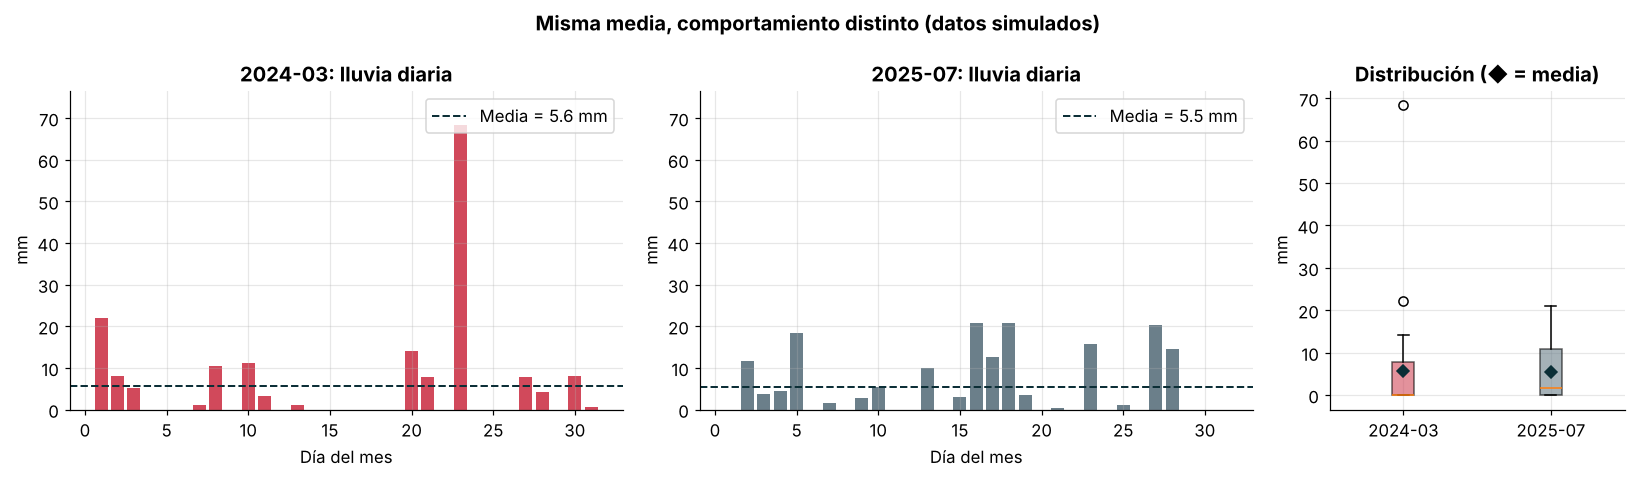

,2024-03,2025-07
Total (mm),172.90,170.50
Media (mm/día),5.58,5.50
Mediana (mm/día),0.00,1.60
Desv. estándar (mm),12.63,7.24
Máximo diario (mm),68.40,20.90
Días sin lluvia,16.00,13.00
Días con ≥ 20 mm,2.00,3.00
% del total en el día más lluvioso,39.56,12.26
Racha seca máxima (días),6.00,3.00


In [10]:
# Tu turno: otra pareja con casi la misma media (≈ 5.5 mm/día). Cambia los periodos: de '2023-01' a '2025-12'
display(comparar_periodos(df, "2024-03", "2025-07"))

---
## Nivel 3 · Enseñar a **investigar**

Ahora la pregunta no la da el profesor con la respuesta incluida; la formulan los estudiantes.

> **Pregunta de investigación:** *¿Cómo se comporta la lluvia a lo largo del año en Caucasia y qué implica para las actividades del territorio?*

Descomponemos la pregunta (pensamiento computacional) en tres sub-preguntas que podemos responder con los datos:
1. ¿Cuándo llueve más y cuánto cambia de un año a otro? *(régimen mensual y variabilidad)*
2. ¿La media representa la lluvia típica de cada mes? *(media vs. mediana)*
3. ¿Qué tan frecuentes son los aguaceros fuertes y las rachas secas? *(eventos extremos)*

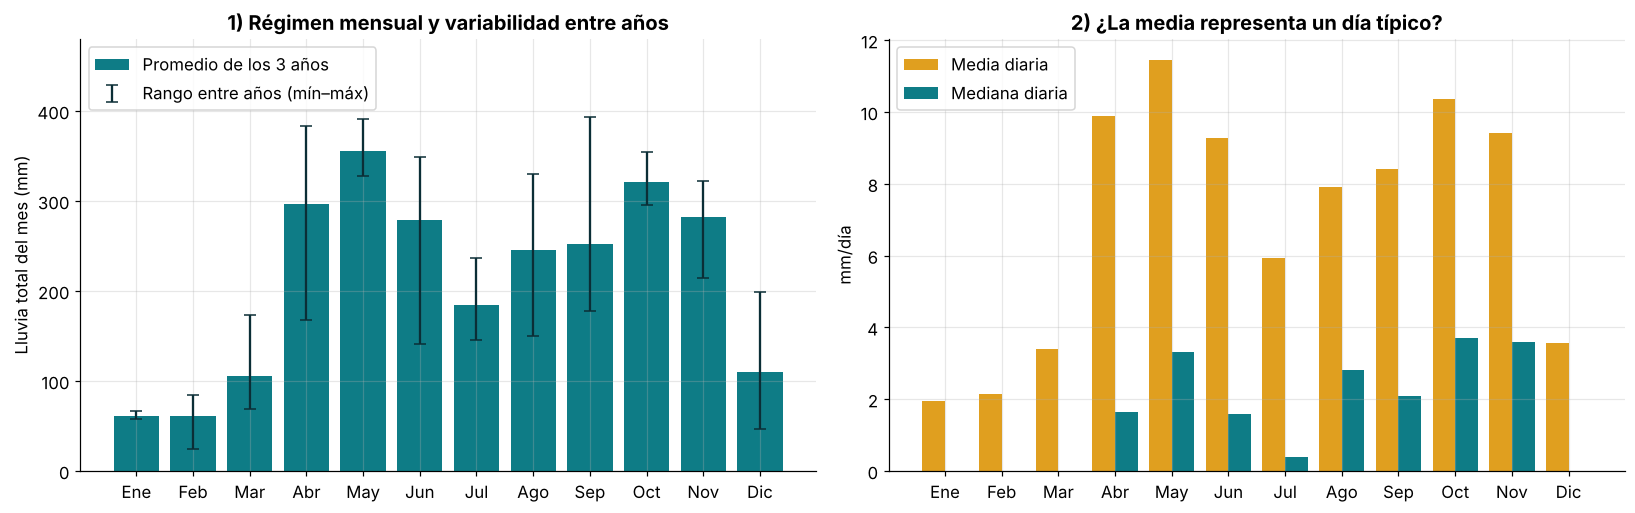

Total anual simulado: {2023: 2766.0, 2024: 2431.0, 2025: 2463.0}
Meses con mediana = 0 mm (más de la mitad de los días sin lluvia): ['Ene', 'Feb', 'Mar', 'Dic']


In [11]:
mensual = (df.groupby(["anio", "mes"])["precipitacion_mm"].sum().unstack("anio"))   # total mensual por año
promedio, minimo, maximo = mensual.mean(axis=1), mensual.min(axis=1), mensual.max(axis=1)

diaria_por_mes = df.groupby("mes")["precipitacion_mm"]
media_dia, mediana_dia = diaria_por_mes.mean(), diaria_por_mes.median()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8))
ax1.bar(MESES, promedio, color=TEAL, label="Promedio de los 3 años")
ax1.errorbar(MESES, promedio, yerr=[promedio - minimo, maximo - promedio], fmt="none",
             ecolor=OSCURO, capsize=4, label="Rango entre años (mín–máx)")
ax1.set_title("1) Régimen mensual y variabilidad entre años")
ax1.set_ylabel("Lluvia total del mes (mm)"); ax1.set_ylim(0, 480); ax1.legend(loc="upper left")

x, ancho = np.arange(12), 0.4
ax2.bar(x - ancho/2, media_dia, ancho, color=AMBAR, label="Media diaria")
ax2.bar(x + ancho/2, mediana_dia, ancho, color=TEAL, label="Mediana diaria")
ax2.set_xticks(x); ax2.set_xticklabels(MESES)
ax2.set_title("2) ¿La media representa un día típico?"); ax2.set_ylabel("mm/día"); ax2.legend()
plt.tight_layout(); plt.show()

print(f"Total anual simulado: {df.groupby('anio')['precipitacion_mm'].sum().round(0).to_dict()}")
print(f"Meses con mediana = 0 mm (más de la mitad de los días sin lluvia): "
      f"{[MESES[m-1] for m in mediana_dia.index if mediana_dia[m] == 0]}")

**Lectura:** en casi todos los meses la **media supera a la mediana**: pocos días muy lluviosos «jalan» el promedio hacia arriba. Un estudiante que solo reporta la media diría que en abril llueve ≈ 10 mm *todos* los días; los datos dicen que la mitad de los días llueve poco o nada y unos cuantos días concentran el agua.

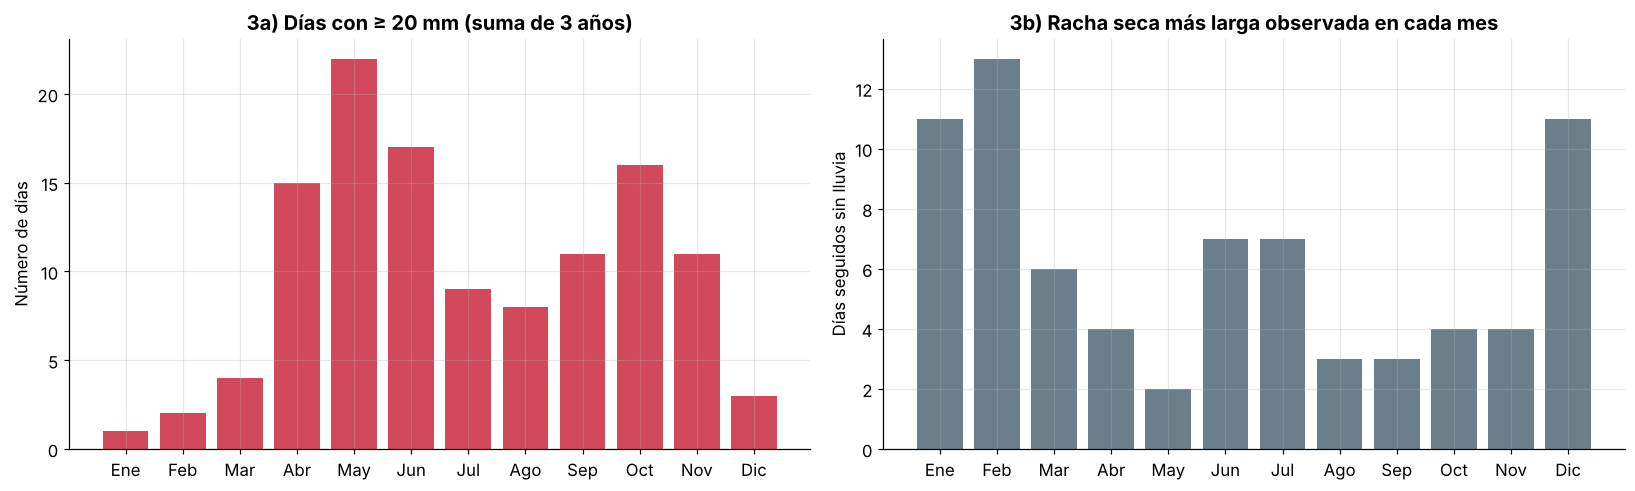

Días con ≥ 20 mm en los 3 años: 119 de 1096 (10.9 %)
Racha seca más larga de toda la serie: 13 días (mes: Feb)


In [12]:
UMBRAL = 20   # mm en un día: cámbialo y observa cómo cambia la conclusión

extremos = (df.assign(fuerte=df["precipitacion_mm"] >= UMBRAL)
              .groupby("mes")["fuerte"].sum())

rachas = (df.groupby(["anio", "mes"])["precipitacion_mm"]
            .apply(racha_seca_maxima).unstack("anio").max(axis=1))   # la peor racha seca de cada mes

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.6))
ax1.bar(MESES, extremos, color=CORAL)
ax1.set_title(f"3a) Días con ≥ {UMBRAL} mm (suma de 3 años)"); ax1.set_ylabel("Número de días")
ax2.bar(MESES, rachas, color=PIZARRA)
ax2.set_title("3b) Racha seca más larga observada en cada mes"); ax2.set_ylabel("Días seguidos sin lluvia")
plt.tight_layout(); plt.show()

print(f"Días con ≥ {UMBRAL} mm en los 3 años: {int(extremos.sum())} de {len(df)} ({100*extremos.sum()/len(df):.1f} %)")
print(f"Racha seca más larga de toda la serie: {int(rachas.max())} días (mes: {MESES[int(rachas.idxmax())-1]})")

### ✋ Detente: la pregunta más importante de la sesión
> *¿Qué otros datos necesitaríamos para estudiar si las lluvias intensas están asociadas con dificultades de movilidad o inundaciones en determinados sectores de Caucasia?*

Con **solo** esta serie de lluvia **no podemos afirmar** que un aguacero cause una inundación: falta información del territorio. La tabla siguiente convierte esa reflexión en un **plan de investigación**.

In [13]:
plan = pd.DataFrame([
    ["¿Dónde se concentran los daños cuando llueve ≥ 20 mm?",
     "Reportes de emergencias por sector y fecha", "Gestión del riesgo municipal / registros locales",
     "Pueden estar incompletos o sub-registrar zonas rurales"],
    ["¿La lluvia de un sitio representa a todo el municipio?",
     "Lluvia en varios puntos (pluviómetros escolares)", "Estaciones oficiales + mediciones del colegio",
     "Una estación puede no reflejar la variación espacial"],
    ["¿Hay drenaje y obras que cambian el efecto de la lluvia?",
     "Mapas de drenaje, pendiente y uso del suelo", "Planeación municipal, cartografía abierta",
     "Información desactualizada o no pública"],
    ["¿El año analizado es típico?",
     "Series de 10–30 años; fenómenos El Niño / La Niña", "IDEAM, NASA POWER (verificar condiciones de uso)",
     "Cambios de instrumentos y vacíos en los registros"],
], columns=["Pregunta investigable", "Datos que faltan", "Fuente posible", "Limitación a declarar"])
display(plan.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"}))

Pregunta investigable,Datos que faltan,Fuente posible,Limitación a declarar
¿Dónde se concentran los daños cuando llueve ≥ 20 mm?,Reportes de emergencias por sector y fecha,Gestión del riesgo municipal / registros locales,Pueden estar incompletos o sub-registrar zonas rurales
¿La lluvia de un sitio representa a todo el municipio?,Lluvia en varios puntos (pluviómetros escolares),Estaciones oficiales + mediciones del colegio,Una estación puede no reflejar la variación espacial
¿Hay drenaje y obras que cambian el efecto de la lluvia?,"Mapas de drenaje, pendiente y uso del suelo","Planeación municipal, cartografía abierta",Información desactualizada o no pública
¿El año analizado es típico?,Series de 10–30 años; fenómenos El Niño / La Niña,"IDEAM, NASA POWER (verificar condiciones de uso)",Cambios de instrumentos y vacíos en los registros


---
## Horizonte · De la estadística a la inteligencia artificial

La lluvia, la humedad y la temperatura no son independientes. Un modelo de *Machine Learning* sencillo (regresión lineal) **aprende** una relación a partir de datos pasados. Pero el pensamiento estadístico exige tres cuidados:

1. **Evaluar con datos que el modelo no vio:** entrenamos con 2023–2024 y probamos con 2025 (respeta el orden del tiempo).
2. **Comparar con una predicción ingenua:** «siempre el promedio». Si el modelo no la supera, no aporta.
3. **Mirar el error en las unidades del problema,** no solo un número como R².

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

def evaluar_modelo(df, objetivo, predictor, corte="2025-01-01"):
    """Entrena con los años anteriores al corte y evalúa con datos que el modelo NO ha visto.
    Compara contra una predicción ingenua: 'siempre el promedio del entrenamiento'."""
    entrenamiento = df[df["fecha"] < corte]
    prueba = df[df["fecha"] >= corte]
    modelo = LinearRegression().fit(entrenamiento[[predictor]], entrenamiento[objetivo])
    prediccion = modelo.predict(prueba[[predictor]])
    ingenua = np.full(len(prueba), entrenamiento[objetivo].mean())
    y = prueba[objetivo]
    return {
        "modelo": modelo, "prueba": prueba, "prediccion": prediccion,
        "rmse_modelo": float(np.sqrt(mean_squared_error(y, prediccion))),
        "rmse_ingenua": float(np.sqrt(mean_squared_error(y, ingenua))),
        "r2_prueba": float(r2_score(y, prediccion)),
    }

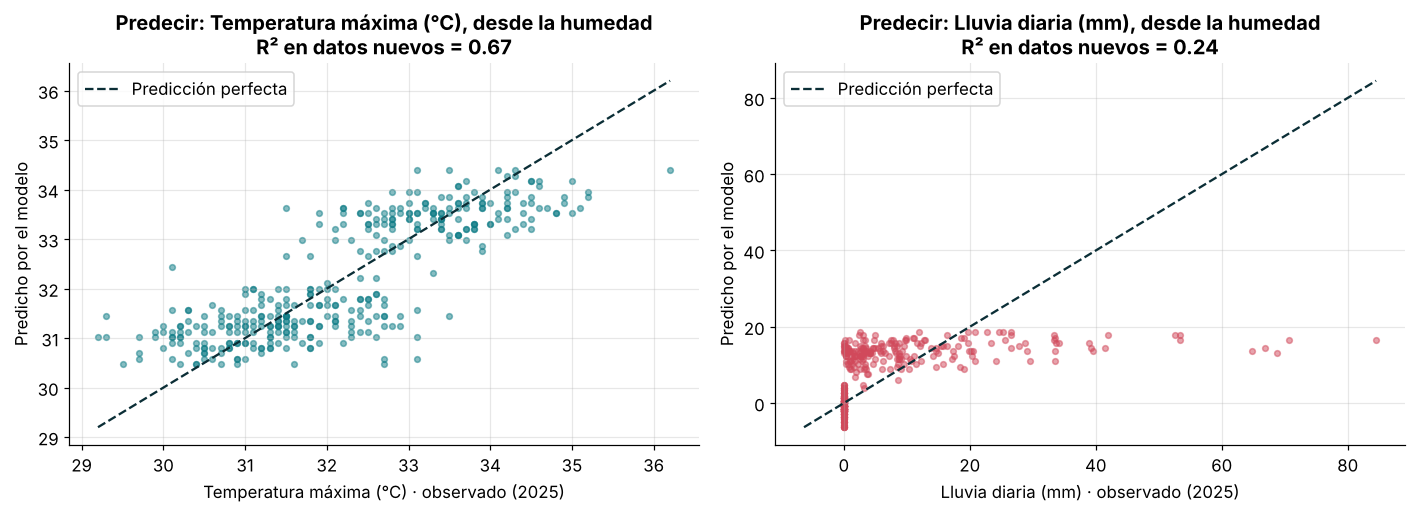

,Error del modelo (RMSE),Error de la predicción ingenua,R² (datos nuevos),Mejora frente a lo ingenuo (%)
Qué predice,,,,
Temperatura máxima (°C),0.78,1.36,0.67,42.55
Lluvia diaria (mm),10.77,12.39,0.24,13.07


In [15]:
casos = [("temp_max_C", "Temperatura máxima (°C)", TEAL), ("precipitacion_mm", "Lluvia diaria (mm)", CORAL)]
resultados = []

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8))
for eje, (objetivo, etiqueta, color) in zip(ejes, casos):
    r = evaluar_modelo(df, objetivo, "humedad_pct")
    real = r["prueba"][objetivo]
    eje.scatter(real, r["prediccion"], s=14, alpha=0.5, color=color)
    lim = [min(real.min(), r["prediccion"].min()), max(real.max(), r["prediccion"].max())]
    eje.plot(lim, lim, color=OSCURO, ls="--", label="Predicción perfecta")
    eje.set_xlabel(f"{etiqueta} · observado (2025)"); eje.set_ylabel("Predicho por el modelo")
    eje.set_title(f"Predecir: {etiqueta}, desde la humedad\nR² en datos nuevos = {r['r2_prueba']:.2f}")
    eje.legend()
    resultados.append({"Qué predice": etiqueta, "Error del modelo (RMSE)": r["rmse_modelo"],
                       "Error de la predicción ingenua": r["rmse_ingenua"], "R² (datos nuevos)": r["r2_prueba"],
                       "Mejora frente a lo ingenuo (%)": 100 * (1 - r["rmse_modelo"] / r["rmse_ingenua"])})
plt.tight_layout(); plt.show()
display(pd.DataFrame(resultados).set_index("Qué predice"))

**Lectura crítica**
* La humedad predice bien la **temperatura máxima** (el error se reduce ≈ 43 % frente a la predicción ingenua).
* Para la **lluvia diaria** el modelo mejora poco y su error sigue siendo grande: la lluvia es muy asimétrica, con muchos ceros y pocos días extremos, y una recta no captura eso (¡incluso predice «lluvias negativas» en algunos días!). *Un modelo puede ejecutarse sin errores y aun así ser poco útil.*
* Recuerda: estos datos son simulados y la relación entre variables **se programó** en la simulación; con datos reales habría que verificarlo.

> Esta es la conexión con la IA: **variables, distribuciones, error, muestreo (entrenamiento/prueba) e incertidumbre** son ideas estadísticas que los estudiantes necesitan para cuestionar a los algoritmos.

---
## Cierre: lo que cambió entre calcular y pensar

| Mismo dato: la media de 6–11 mm | **Calcular** | **Pensar estadísticamente** |
|---|---|---|
| Pregunta | ¿Cuánto da la media? | ¿Qué significa, qué oculta y qué más necesito saber? |
| Evidencia | Un número | Número + gráfico + mediana + dispersión + contexto |
| Python sirve para… | Ahorrar tiempo | Experimentar, buscar patrones y verificar |
| Resultado | Respuesta correcta | Explicación argumentada con límites declarados |

### Una progresión para el aula
* **Primaria:** registrar lluvia con un pluviómetro casero, tablas de frecuencia y pictogramas («días con lluvia / sin lluvia»); preguntar *¿cuál semana fue más lluviosa y por qué?*
* **Secundaria básica:** media, mediana, rango y desviación; construir gráficos; comparar dos semanas o meses con la misma media.
* **Educación media:** series de tiempo, correlación y regresión; entrenar/evaluar un modelo; discutir sesgos y límites de las predicciones.

### Tres afirmaciones para llevar
1. **Enseñar estadística es enseñar a pensar:** no basta calcular, hay que interpretar.
2. **Enseñar estadística es enseñar a investigar:** preguntas → datos → patrones → explicaciones → límites.
3. **Enseñar estadística es preparar para comprender la IA:** datos, incertidumbre, error y sesgo.

---
### ❓ ¿Estamos enseñando a nuestros estudiantes a **calcular con datos** o a **pensar con datos**?